## Importing Python Packages

In [16]:
# ====== Core Python Libraries ======
import os
import re

# ====== Data Handling ======
import numpy as np
import pandas as pd

# ====== Visualization ======
import matplotlib.pyplot as plt
import seaborn as sns

# ====== NLP (NLTK) ======
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# ====== Scikit-learn: Model Selection ======
from sklearn.model_selection import train_test_split

# ====== Scikit-learn: Feature Extraction ======
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    CountVectorizer,
    HashingVectorizer
)

# ====== Scikit-learn: Preprocessing ======
from sklearn.preprocessing import StandardScaler,LabelEncoder

# ====== Scikit-learn: Machine Learning Models ======
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)

# ====== Boosting Libraries ======
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ====== Scikit-learn: Evaluation Metrics ======
 

# ====== Sparse Matrix Utilities ======
from scipy.sparse import csr_matrix, hstack

# ====== Model Saving ======
import joblib

# ====== Progress Bar ======
from tqdm import tqdm

In [17]:
# Download required NLTK data (run once)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

In [18]:
Model_Folder_Name = 'TF_IDF_NN'
os.makedirs(Model_Folder_Name, exist_ok=True)

## Dataset

In [19]:
path = r"C:\Users\AISHWARYA\OneDrive\Desktop\major_project\benchmark_results.csv"
df = pd.read_csv(path)

In [20]:
df

,QueryID,Level,NL_Query,Expected_SQL,Generated_SQL,Execution_Success,Generated_Rows,Expected_Rows,Exact_Match,Value_Match_Pct,Row_Match_Pct,Col_Match_Pct,Confidence_Score,Operation_Match,Column_Match,Generation_Time_s
0,1,Simple,Show all sales from the North region,SELECT * FROM data WHERE Region = 'North',SELECT * FROM data WHERE Region = 'North',True,206,206,True,100,100.0,100.0,100.0,100.0,100.0,28.68
1,2,Simple,List all products sold in 2024,SELECT * FROM data WHERE Year = 2024,SELECT DISTINCT Product\nFROM data\nWHERE Year...,True,10,346,False,0,2.9,5.9,100.0,100.0,100.0,5.43
2,3,Simple,Show orders with total sales above 5000,SELECT * FROM data WHERE TotalSales > 5000,SELECT * FROM data WHERE TotalSales > 5000,True,344,344,True,100,100.0,100.0,66.7,0.0,100.0,4.73
3,4,Simple,Display all laptop orders,SELECT * FROM data WHERE Product = 'Laptop',SELECT * FROM data WHERE Product = 'Laptop',True,86,86,True,100,100.0,100.0,93.3,100.0,80.0,3.49
4,5,Simple,List the first 10 records,SELECT * FROM data LIMIT 10,SELECT * FROM data LIMIT 10,True,10,10,True,100,100.0,100.0,93.3,100.0,80.0,3.35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,96,Complex,Show regions where all products have been sold,SELECT Region FROM data GROUP BY Region HAVING...,SELECT Region FROM data GROUP BY Region HAVING...,True,5,5,True,100,100.0,100.0,66.7,100.0,100.0,7.72
396,97,Complex,Average order value trend by quarter and year,"SELECT Year, Quarter, AVG(TotalSales) FROM dat...","SELECT\n STRFTIME('%Y', Date) AS Year,\n STR...",True,36,12,False,0,0.0,66.7,100.0,100.0,100.0,16.93
397,98,Complex,Cumulative sum of quantity sold per product or...,"SELECT Product, Date, Quantity, SUM(Quantity) ...","SELECT\n Date,\n Product,\n SUM(Quantity) O...",True,1000,1000,False,0,100.0,50.0,75.0,50.0,100.0,8.56
398,99,Complex,Products that are only sold through online cus...,SELECT Product FROM data GROUP BY Product HAVI...,SELECT DISTINCT Product\nFROM data\nWHERE Cust...,True,10,0,False,50,0.0,100.0,100.0,100.0,100.0,150.01


In [21]:
Target_Col = "Execution_Success"

In [35]:

class_names = [str(x) for x in sorted(df['Execution_Success'].unique())]
print("Classes:", class_names)

Classes: ['False', 'True']


## NLP Preprocessing

In [36]:
def preprocess_text(text):
    """
    NLP Preprocessing: lowercase, remove punctuation, remove stopwords, lemmatize.
    """
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabetic characters
    stop_words = set(stopwords.words('english'))
    lemmatizer = WordNetLemmatizer()
    words = text.split()
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words and len(word) > 2]
    return ' '.join(words)

def get_preprocessed_data(df, target_col):
    preprocessed_path = f'{Model_Folder_Name}/preprocessed.pkl'
    
    if os.path.exists(preprocessed_path):
        print("Loading preprocessed data...")
        return joblib.load(preprocessed_path)
    else:
        print("Preprocessing text...")

        processed_cols = {}

        numeric_df = df.select_dtypes(include=['number'])
        target_df = df[[target_col]]

        for col in df.columns:
            if col != target_col and df[col].dtype == object:
                processed_cols[f"{col}_processed"] = [
                    preprocess_text(text) for text in tqdm(
                        df[col].astype(str),
                        desc=f"Preprocessing {col}"
                    )
                ]

        processed_text_df = pd.DataFrame(processed_cols)

        final_df = pd.concat([
            numeric_df.reset_index(drop=True),
            processed_text_df.reset_index(drop=True),
            target_df.reset_index(drop=True)
        ], axis=1)

        joblib.dump(final_df, preprocessed_path)
        print("Preprocessed data saved.")

        return final_df

In [37]:
df = get_preprocessed_data(df, target_col=Target_Col)
df

Loading preprocessed data...


,QueryID,Generated_Rows,Expected_Rows,Value_Match_Pct,Row_Match_Pct,Col_Match_Pct,Confidence_Score,Operation_Match,Column_Match,Generation_Time_s,Level_processed,NL_Query_processed,Expected_SQL_processed,Generated_SQL_processed,Execution_Success
0,1,206,206,100,100.0,100.0,100.0,100.0,100.0,28.68,simple,show sale north region,select data region north,select data region north,True
1,2,10,346,0,2.9,5.9,100.0,100.0,100.0,5.43,simple,list product sold,select data year,select distinct product data year,True
2,3,344,344,100,100.0,100.0,66.7,0.0,100.0,4.73,simple,show order total sale,select data totalsales,select data totalsales,True
3,4,86,86,100,100.0,100.0,93.3,100.0,80.0,3.49,simple,display laptop order,select data product laptop,select data product laptop,True
4,5,10,10,100,100.0,100.0,93.3,100.0,80.0,3.35,simple,list first record,select data limit,select data limit,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,96,5,5,100,100.0,100.0,66.7,100.0,100.0,7.72,complex,show region product sold,select region data group region countdistinct ...,select region data group region countdistinct ...,True
396,97,36,12,0,0.0,66.7,100.0,100.0,100.0,16.93,complex,average order value trend quarter year,select year quarter avgtotalsales data group y...,select strftimey date year strftimem date mont...,True
397,98,1000,1000,0,100.0,50.0,75.0,50.0,100.0,8.56,complex,cumulative sum quantity sold per product order...,select product date quantity sumquantity parti...,select date product sumquantity partition prod...,True
398,99,10,0,50,0.0,100.0,100.0,100.0,100.0,150.01,complex,product sold online customer,select product data group product countdistinc...,select distinct product data customertype online,True


## Feature Extraction Vectorization

In [38]:
def get_vectorized_data(df, target_col, method="Uni-Gram"):

    safe_method = method.replace(" ", "_").replace("-", "_")

    tfidf_path = f"{Model_Folder_Name}/vectorized_{safe_method}.pkl"
    vectorizer_path = f"{Model_Folder_Name}/vectorizer_{safe_method}.pkl"
    scaler_path = f"{Model_Folder_Name}/scaler.pkl"

    if os.path.exists(tfidf_path) and os.path.exists(vectorizer_path):
        print("Loading vectorized data...")
        X = joblib.load(tfidf_path)
        vectorizer = joblib.load(vectorizer_path)
        scaler = joblib.load(scaler_path) if os.path.exists(scaler_path) else None
        return X, vectorizer, scaler

    print(f"Computing vectorization using method: {method}")

    text_cols = [col for col in df.columns if col.endswith('_processed')]
    num_df = df.select_dtypes(include=['number'])

    merged_text = df[text_cols].fillna('').agg(' '.join, axis=1)

    if method == "Uni-Gram":
        vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 1))
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Bi-Gram":
        vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Char-Gram":
        vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 5))
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Count-Vec":
        vectorizer = CountVectorizer(max_features=5000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Hash-Vec":
        vectorizer = HashingVectorizer(n_features=5000, alternate_sign=False)
        X_text = vectorizer.transform(merged_text)

    elif method == "Sublinear-TF":
        vectorizer = TfidfVectorizer(sublinear_tf=True, max_features=6000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "TFIDF-BiTri":
        vectorizer = TfidfVectorizer(ngram_range=(2, 3), max_features=7000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Binary-Count":
        vectorizer = CountVectorizer(binary=True, max_features=6000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "CharWide-Gram":
        vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 7), max_features=8000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Light-Hash":
        vectorizer = HashingVectorizer(n_features=10000, alternate_sign=False)
        X_text = vectorizer.transform(merged_text)

    elif method == "Bag-of-Words":
        vectorizer = CountVectorizer(max_features=7000, stop_words='english')
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "BM25-Style":
        vectorizer = TfidfVectorizer(
            max_features=8000,
            norm=None,
            use_idf=True,
            smooth_idf=True,
            sublinear_tf=True
        )
        X_text = vectorizer.fit_transform(merged_text)

    else:
        raise ValueError("Invalid method selected")

    if num_df.shape[1] > 0:
        scaler = StandardScaler()
        X_num_scaled = scaler.fit_transform(num_df.values)
        X_num_sparse = csr_matrix(X_num_scaled)
        X = hstack([X_text, X_num_sparse])
        joblib.dump(scaler, scaler_path)
    else:
        print("⚠️ No numerical columns found — using only NLP features")
        X = X_text
        scaler = None

    joblib.dump(X, tfidf_path)
    joblib.dump(vectorizer, vectorizer_path)

    print("Final feature matrix X saved successfully.")
    return X, vectorizer, scaler

In [39]:
X, vectorizer, scaler = get_vectorized_data(df, target_col=Target_Col, method="Bag-of-Words")

Loading vectorized data...


In [40]:
y = df[Target_Col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (320, 181) Test shape: (80, 181)


## Common Function for All DL Models Performance Evaluation

In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

def evaluate_model(y_test, y_pred, class_names):
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f"Accuracy (A):  {acc:.4f}")
    print(f"Precision (P): {precision:.4f}")
    print(f"Recall (R):    {recall:.4f}")
    print(f"F1-Score:      {f1:.4f}")

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title("Confusion Matrix")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.show()

    print("\nClassification Report (CR):\n")
    print(classification_report( y_test,y_pred,target_names=[str(x) for x in class_names]))



## DL Python Packages

In [42]:
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.layers import LSTM, GRU, Bidirectional
from tensorflow.keras.utils import to_categorical

## Data Conversion as per DL Format

In [43]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

joblib.dump(le, f"{Model_Folder_Name}/label_encoder.pkl")

num_classes = len(np.unique(y_train_enc))

y_train_cat = to_categorical(y_train_enc, num_classes)
y_test_cat = to_categorical(y_test_enc, num_classes)

X_train_new = X_train.toarray().astype(np.float32)
X_test_new = X_test.toarray().astype(np.float32)

## DNN

In [44]:
import os
import pickle
import matplotlib.pyplot as plt

def save_history(history, history_path):
    """
    Save Keras training history
    """
    with open(history_path, "wb") as f:
        pickle.dump(history.history, f)

def load_history(history_path):
    """
    Load saved history
    """
    if os.path.exists(history_path):
        with open(history_path, "rb") as f:
            return pickle.load(f)
    return None

def plot_training_history(history_path, model_name="Model"):

    history_dict = load_history(history_path)

    if history_dict is None:
        print("History file not found:", history_path)
        return

    # Accuracy
    plt.figure(figsize=(8, 5))
    plt.plot(history_dict['accuracy'], linewidth=2, label='Training Accuracy')
    plt.plot(history_dict['val_accuracy'], linewidth=2, label='Validation Accuracy')
    plt.title(f'{model_name} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Loss
    plt.figure(figsize=(8, 5))
    plt.plot(history_dict['loss'], linewidth=2, label='Training Loss')
    plt.plot(history_dict['val_loss'], linewidth=2, label='Validation Loss')
    plt.title(f'{model_name} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

DNN Loaded
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


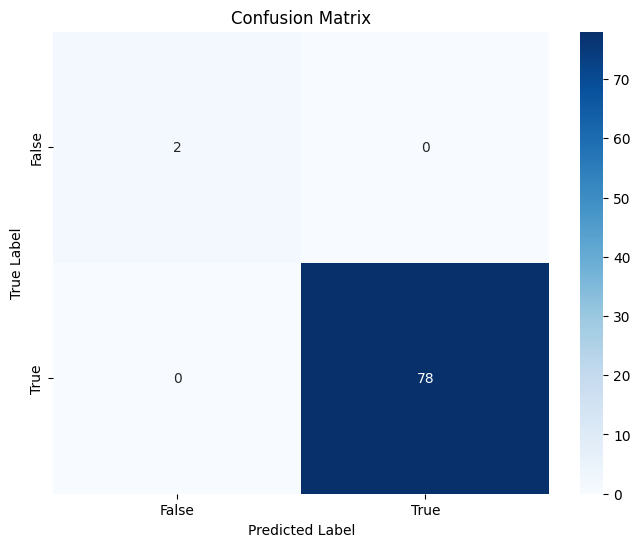


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



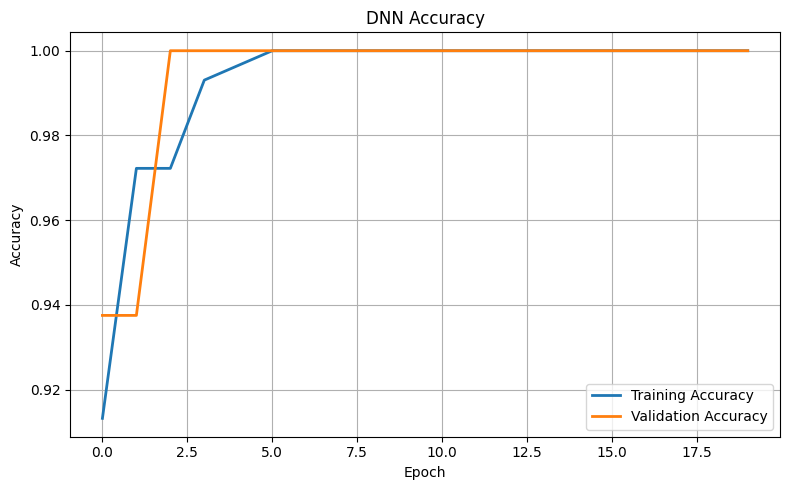

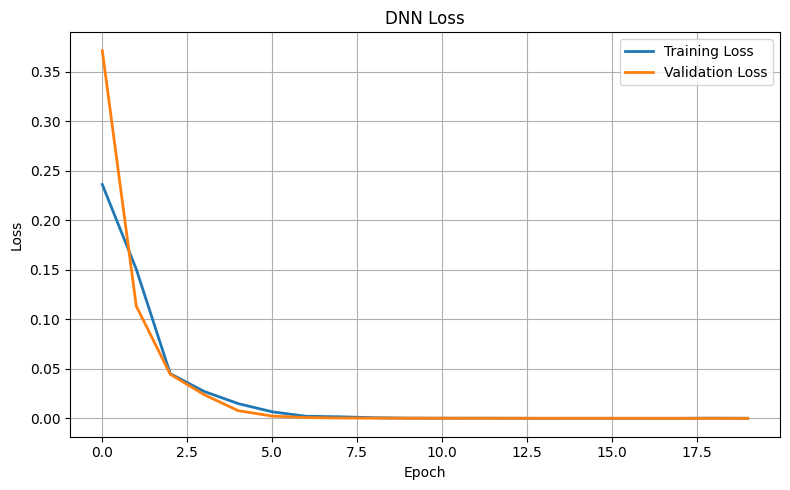

In [45]:
model_path = f"{Model_Folder_Name}/DNN_model.keras"
history_path = f"{Model_Folder_Name}/DNN_history.pkl"

if os.path.exists(model_path):

    model = load_model(model_path)
    print("DNN Loaded")

else:

    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(512, activation='relu'),
        Dropout(0.3),

        Dense(256, activation='relu'),
        Dropout(0.3),

        Dense(128, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train_new,
        y_train_cat,
        epochs=20,
        batch_size=32,
        validation_split=0.1
    )

    model.save(model_path)

    save_history(history, history_path)

pred = np.argmax(model.predict(X_test_new), axis=1)

evaluate_model(
    y_test_enc,
    pred,
    le.classes_
)

plot_training_history(
    history_path,
    model_name="DNN"
)

## CNN

CNN Loaded
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


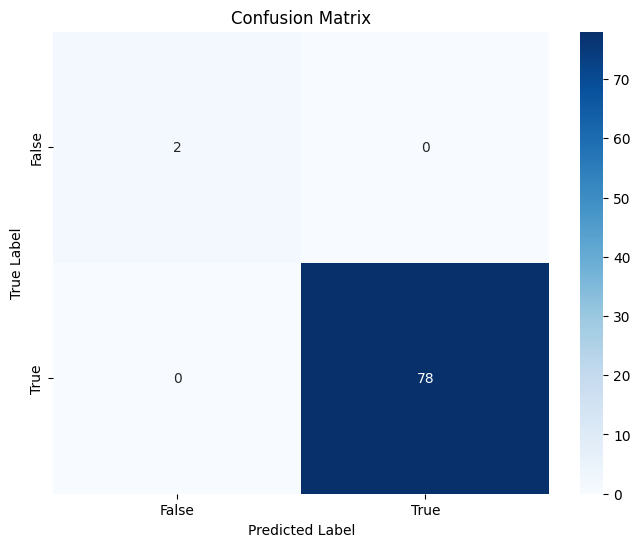


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



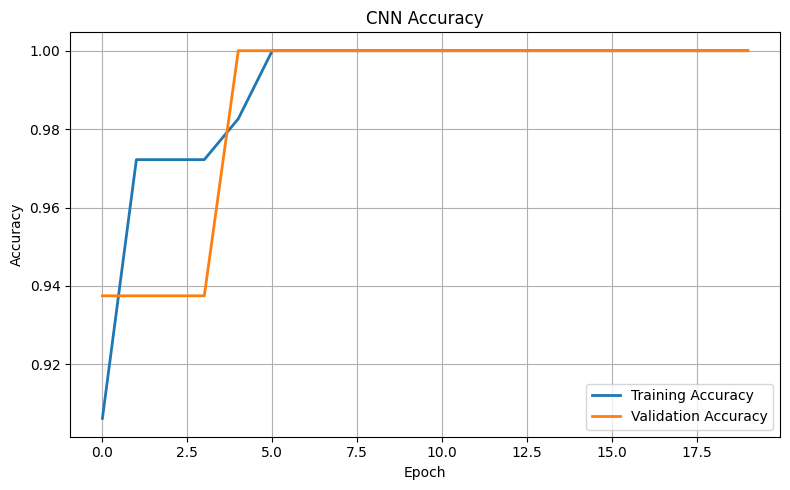

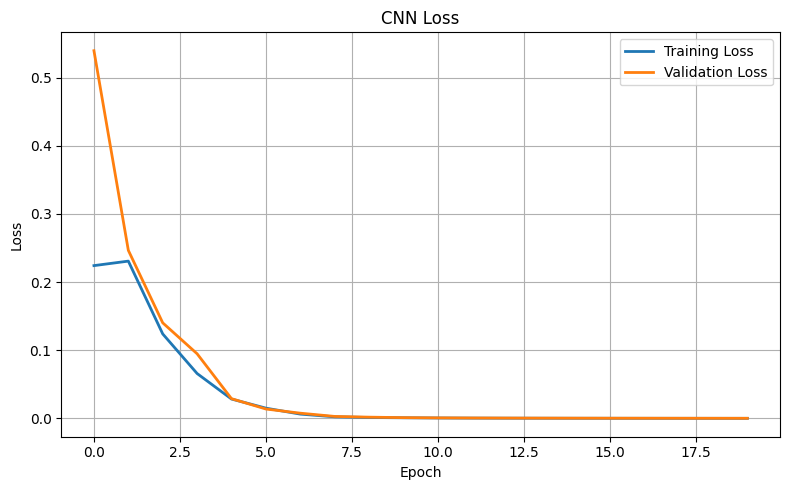

In [46]:
model_path = f"{Model_Folder_Name}/CNN_model.keras"
history_path = f"{Model_Folder_Name}/CNN_history.pkl"

X_train_cnn = X_train_new.reshape(
    X_train_new.shape[0],
    X_train_new.shape[1],
    1
)

X_test_cnn = X_test_new.reshape(
    X_test_new.shape[0],
    X_test_new.shape[1],
    1
)

if os.path.exists(model_path):

    model = load_model(model_path)
    print("CNN Loaded")

else:

    model = Sequential([

        Input(shape=(X_train_cnn.shape[1], 1)),

        Conv1D(128, 3, activation='relu'),
        MaxPooling1D(2),

        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(2),

        Flatten(),

        Dense(128, activation='relu'),

        Dense(num_classes, activation='softmax')

    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train_cnn,
        y_train_cat,
        epochs=20,
        batch_size=32,
        validation_split=0.1
    )

    model.save(model_path)

    save_history(history, history_path)

pred = np.argmax(model.predict(X_test_cnn), axis=1)

evaluate_model(
    y_test_enc,
    pred,
    le.classes_
)

plot_training_history(
    history_path,
    model_name="CNN"
)

# RNN-LSTM

RNN-LSTM Loaded
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 143ms/step
Accuracy (A):  0.9625
Precision (P): 0.9503
Recall (R):    0.9625
F1-Score:      0.9564


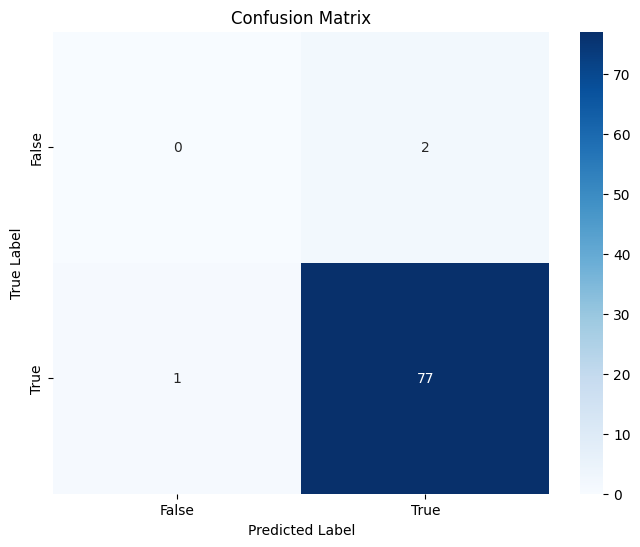


Classification Report (CR):

              precision    recall  f1-score   support

       False       0.00      0.00      0.00         2
        True       0.97      0.99      0.98        78

    accuracy                           0.96        80
   macro avg       0.49      0.49      0.49        80
weighted avg       0.95      0.96      0.96        80



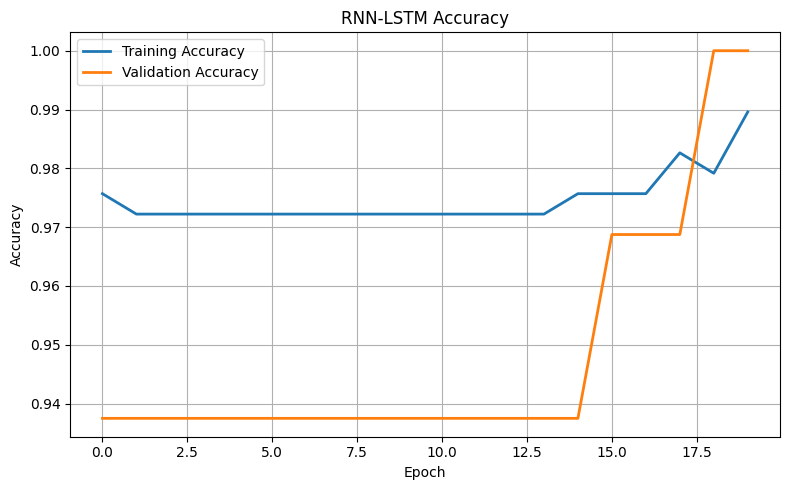

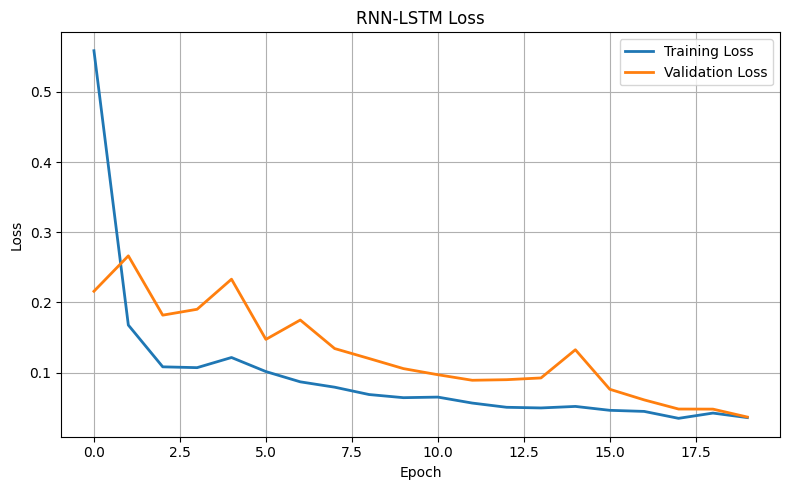

In [47]:
model_path = f"{Model_Folder_Name}/RNN_LSTM_model.keras"
history_path = f"{Model_Folder_Name}/RNN_LSTM_history.pkl"

X_train_rnn = X_train_new.reshape(
    X_train_new.shape[0],
    X_train_new.shape[1],
    1
)

X_test_rnn = X_test_new.reshape(
    X_test_new.shape[0],
    X_test_new.shape[1],
    1
)

if os.path.exists(model_path):

    model = load_model(model_path)
    print("RNN-LSTM Loaded")

else:

    model = Sequential([

        Input(shape=(X_train_rnn.shape[1], 1)),

        LSTM(128),

        Dense(128, activation='relu'),

        Dense(num_classes, activation='softmax')

    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train_rnn,
        y_train_cat,
        epochs=20,
        batch_size=32,
        validation_split=0.1
    )

    model.save(model_path)

    save_history(history, history_path)

pred = np.argmax(model.predict(X_test_rnn), axis=1)

evaluate_model(
    y_test_enc,
    pred,
    le.classes_
)

plot_training_history(
    history_path,
    model_name="RNN-LSTM"
)

## RNN-BiLSTM

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 152ms/step - accuracy: 0.9722 - loss: 0.5954 - val_accuracy: 0.9375 - val_loss: 0.4907
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.9722 - loss: 0.3474 - val_accuracy: 0.9375 - val_loss: 0.2373
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.9722 - loss: 0.1183 - val_accuracy: 0.9375 - val_loss: 0.1414
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.9722 - loss: 0.0731 - val_accuracy: 0.9375 - val_loss: 0.1037
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.9792 - loss: 0.0661 - val_accuracy: 0.9375 - val_loss: 0.0823
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.9722 - loss: 0.0586 - val_accuracy: 0.9375 - val_loss: 0.0820
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 0.9688 - loss: 0.0497 - val_accuracy: 0.9688 - val_loss: 0.0592
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.9757 - loss: 0.0435 - val_accuracy: 0.9375 - val_loss: 0.068

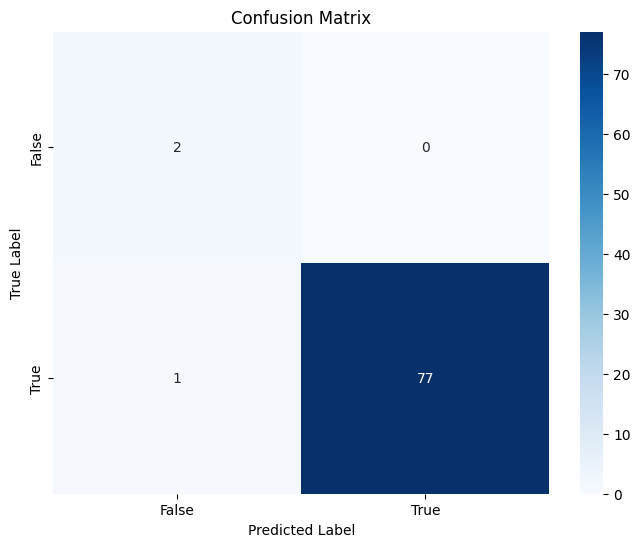


Classification Report (CR):

              precision    recall  f1-score   support

       False       0.67      1.00      0.80         2
        True       1.00      0.99      0.99        78

    accuracy                           0.99        80
   macro avg       0.83      0.99      0.90        80
weighted avg       0.99      0.99      0.99        80



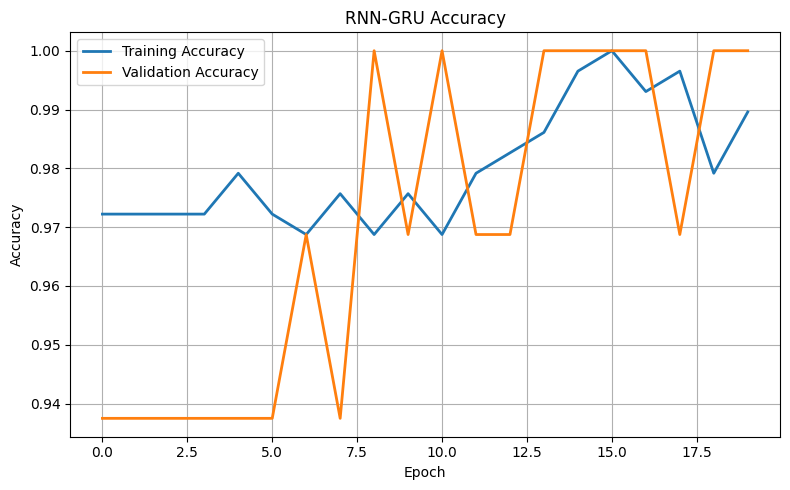

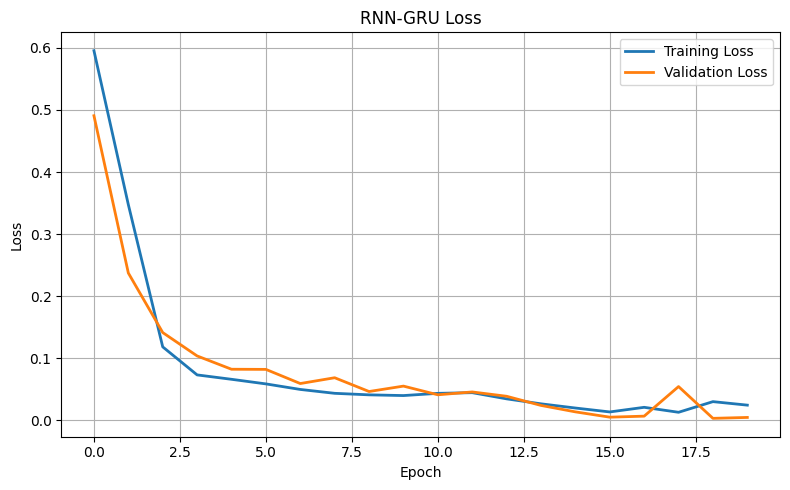

In [48]:
model_path = f"{Model_Folder_Name}/RNN_GRU_model.keras"
history_path = f"{Model_Folder_Name}/RNN_GRU_history.pkl"

if os.path.exists(model_path):

    model = load_model(model_path)
    print("RNN-GRU Loaded")

else:

    model = Sequential([

        Input(shape=(X_train_rnn.shape[1], 1)),

        GRU(128),

        Dense(128, activation='relu'),

        Dense(num_classes, activation='softmax')

    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train_rnn,
        y_train_cat,
        epochs=20,
        batch_size=32,
        validation_split=0.1
    )

    model.save(model_path)

    save_history(history, history_path)

pred = np.argmax(model.predict(X_test_rnn), axis=1)

evaluate_model(
    y_test_enc,
    pred,
    le.classes_
)

plot_training_history(
    history_path,
    model_name="RNN-GRU"
)

## RNN-BiGRU

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 265ms/step - accuracy: 0.9167 - loss: 0.5560 - val_accuracy: 0.9375 - val_loss: 0.3897
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 137ms/step - accuracy: 0.9722 - loss: 0.2200 - val_accuracy: 0.9375 - val_loss: 0.1948
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step - accuracy: 0.9722 - loss: 0.0813 - val_accuracy: 0.9688 - val_loss: 0.0861
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 167ms/step - accuracy: 0.9722 - loss: 0.0527 - val_accuracy: 0.9688 - val_loss: 0.0673
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step - accuracy: 0.9722 - loss: 0.0440 - val_accuracy: 0.9688 - val_loss: 0.0616
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - accuracy: 0.9792 - loss: 0.0497 - val_accuracy: 1.0000 - val_loss: 0.0550
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 253ms/step - accuracy: 0.9826 - loss: 0.0445 - val_accuracy: 0.9688 - val_loss: 0.0501
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 183ms/step - accuracy: 0.9826 - loss: 0.0381 - val_accuracy: 0.9688 - val_loss:

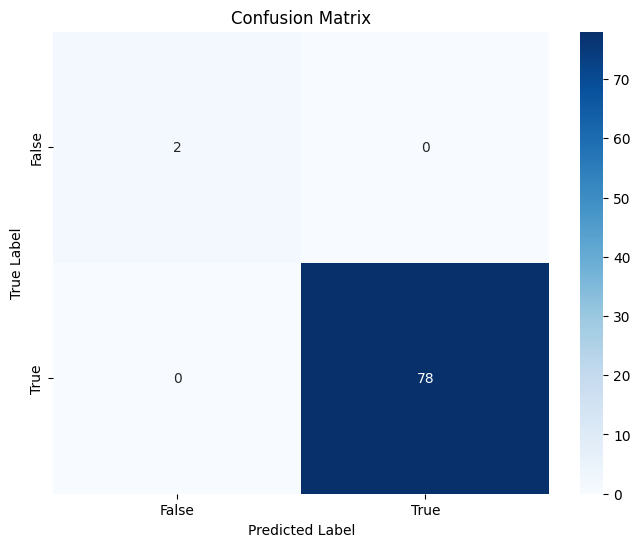


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



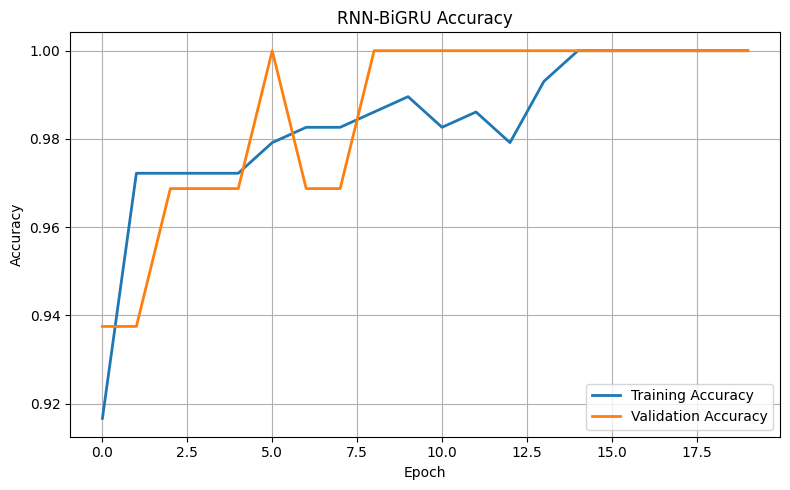

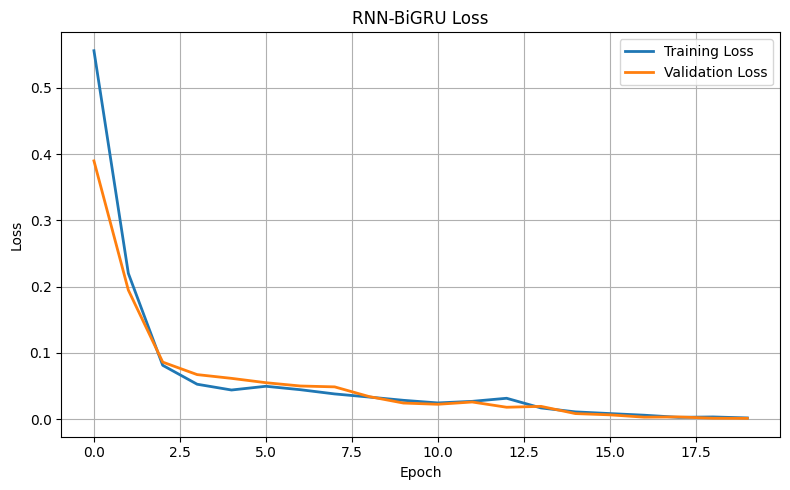

In [49]:
model_path = f"{Model_Folder_Name}/RNN_BIGRU_model.keras"
history_path = f"{Model_Folder_Name}/RNN_BIGRU_history.pkl"

if os.path.exists(model_path):

    model = load_model(model_path)
    print("RNN-BiGRU Loaded")

else:

    model = Sequential([

        Input(shape=(X_train_rnn.shape[1], 1)),

        Bidirectional(
            GRU(128)
        ),

        Dense(128, activation='relu'),

        Dense(num_classes, activation='softmax')

    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train_rnn,
        y_train_cat,
        epochs=20,
        batch_size=32,
        validation_split=0.1
    )

    model.save(model_path)

    save_history(history, history_path)

pred = np.argmax(model.predict(X_test_rnn), axis=1)

evaluate_model(
    y_test_enc,
    pred,
    le.classes_
)

plot_training_history(
    history_path,
    model_name="RNN-BiGRU"
)